<a href="https://colab.research.google.com/github/priyaselvam1431/Assignment---1/blob/main/Mini_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Install and Import library

In [ ]:
!pip -q install requests pandas

In [ ]:
import requests
import pandas as pd
import time

#API set nd scraping


In [ ]:
api_url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

row_limit = 100000
batch_size = 500

all_records= []



In [ ]:
#unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,lalitude,longitude

In [ ]:
import requests
import pandas as pd

all_records = []

row_limit = 100000
batch_size = 5000

for offset in range(0, row_limit, batch_size):

    parameters = {
        "$select": "unique_key,created_date,closed_date,agency,complaint_type,descriptor,borough,status,latitude,longitude",
        "$limit": batch_size,
        "$offset": offset,
        "$order": "created_date DESC"
    }

    response = requests.get(api_url, params=parameters, timeout=30)

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    batch_records = response.json()

    # Replace missing and empty values with NULL
    for record in batch_records:
        for column in record:
            if record[column] is None or record[column] == "":
                record[column] = None

    all_records.extend(batch_records)

    print("Records collected:", len(all_records))

    if len(batch_records) < batch_size:
        print("No more records returned.")
        break

# Convert into DataFrame
df = pd.DataFrame(all_records)

# Replace NaN with None
df = df.astype(object).where(pd.notna(df), None)

print("\nTotal records:", len(df))

# Check NULL values
print("\nNULL value count:")
print(df.isnull().sum())



HTTP status: 200
Records collected: 5000
HTTP status: 200
Records collected: 10000
HTTP status: 200
Records collected: 15000
HTTP status: 200
Records collected: 20000
HTTP status: 200
Records collected: 25000
HTTP status: 200
Records collected: 30000
HTTP status: 200
Records collected: 35000
HTTP status: 200
Records collected: 40000
HTTP status: 200
Records collected: 45000
HTTP status: 200
Records collected: 50000
HTTP status: 200
Records collected: 55000
HTTP status: 200
Records collected: 60000
HTTP status: 200
Records collected: 65000
HTTP status: 200
Records collected: 70000
HTTP status: 200
Records collected: 75000
HTTP status: 200
Records collected: 80000
HTTP status: 200
Records collected: 85000
HTTP status: 200
Records collected: 90000
HTTP status: 200
Records collected: 95000
HTTP status: 200
Records collected: 100000

Total records: 100000

NULL value count:
unique_key            0
created_date          0
agency                0
complaint_type        0
descriptor            

# Convert collected records into dataframe

In [ ]:
nyc311_df = pd.DataFrame(all_records)

print("Rows collected:", len(nyc311_df))
print("Columns collected:", len(nyc311_df.columns))

nyc311_df.head()

Rows collected: 100000
Columns collected: 10


,unique_key,created_date,agency,complaint_type,descriptor,borough,status,latitude,longitude,closed_date
0,71044266,2026-11-09T02:06:35.000,DEP,Noise,Construction,BROOKLYN,In Progress,40.67582818448727,-73.9895378695026,NaN
1,71044500,2026-11-09T02:06:32.000,NYPD,Noise - Residential,Loud Music/Party,BROOKLYN,In Progress,40.66741351273327,-73.86035785184494,NaN
2,71050770,2026-11-09T02:06:24.000,TLC,For Hire Vehicle Complaint,Driver Complaint - Non Passenger,MANHATTAN,In Progress,40.713066073268486,-74.01404988425595,NaN
3,71050000,2026-11-09T02:06:12.000,NYPD,Noise - Residential,Banging/Pounding,QUEENS,In Progress,40.7618671322135,-73.82120999786123,NaN
4,71045758,2026-11-09T02:04:37.000,NYPD,Illegal Parking,Blocked Hydrant,BROOKLYN,In Progress,40.64645665347714,-74.00531524785919,NaN


# Check cloumn names and datatypes


In [ ]:
print("Column names:")
print(nyc311_df.columns)

print("\nDatatypes")
print(nyc311_df.dtypes)


Column names:
Index(['unique_key', 'created_date', 'agency', 'complaint_type', 'descriptor',
       'borough', 'status', 'latitude', 'longitude', 'closed_date'],
      dtype='object')

Datatypes
unique_key        object
created_date      object
agency            object
complaint_type    object
descriptor        object
borough           object
status            object
latitude          object
longitude         object
closed_date       object
dtype: object


#Save scrapped data into CSV file

In [ ]:
csv_file = "nyc311_row_sample.csv"

nyc311_df.to_csv(csv_file, index =False)
print("Saved file:", csv_file)

from google.colab import files
files.download(csv_file)


Saved file: nyc311_row_sample.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Data Cleaning

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Load the data set

In [ ]:
df = pd.read_csv("nyc311_row_sample.csv")

print(df.head())

   unique_key             created_date agency              complaint_type  \
0    71044266  2026-11-09T02:06:35.000    DEP                       Noise   
1    71044500  2026-11-09T02:06:32.000   NYPD         Noise - Residential   
2    71050770  2026-11-09T02:06:24.000    TLC  For Hire Vehicle Complaint   
3    71050000  2026-11-09T02:06:12.000   NYPD         Noise - Residential   
4    71045758  2026-11-09T02:04:37.000   NYPD             Illegal Parking   

                         descriptor    borough       status   latitude  \
0                      Construction   BROOKLYN  In Progress  40.675828   
1                  Loud Music/Party   BROOKLYN  In Progress  40.667414   
2  Driver Complaint - Non Passenger  MANHATTAN  In Progress  40.713066   
3                  Banging/Pounding     QUEENS  In Progress  40.761867   
4                   Blocked Hydrant   BROOKLYN  In Progress  40.646457   

   longitude closed_date  
0 -73.989538         NaN  
1 -73.860358         NaN  
2 -74.01405

# Check dataset information

In [ ]:
print(df.shape)
print(df.info())
print(df.describe())

(100000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   unique_key      100000 non-null  int64  
 1   created_date    100000 non-null  object 
 2   agency          100000 non-null  object 
 3   complaint_type  100000 non-null  object 
 4   descriptor      97725 non-null   object 
 5   borough         100000 non-null  object 
 6   status          100000 non-null  object 
 7   latitude        98557 non-null   float64
 8   longitude       98557 non-null   float64
 9   closed_date     74890 non-null   object 
dtypes: float64(2), int64(1), object(7)
memory usage: 7.6+ MB
None
         unique_key      latitude     longitude
count  1.000000e+05  98557.000000  98557.000000
mean   7.100156e+07     40.733391    -73.926280
std    3.063746e+04      0.083179      0.075212
min    7.094413e+07     40.499540    -74.252172
25%    7.097518e+0

# Check and handling missing values

In [ ]:
print(df.isnull().sum())

df['borough'] = df ['borough'].fillna('Unknown')
df['Compliant_type'] = df.complaint_type.fillna('Unknown')


unique_key            0
created_date          0
agency                0
complaint_type        0
descriptor         2275
borough               0
status                0
latitude           1443
longitude          1443
closed_date       25110
dtype: int64


# Remove Duplicate records

In [ ]:
df = df.drop_duplicates(subset=['unique_key'])

print("Duplicates removed")


Duplicates removed


# Correct date format

In [ ]:
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')


# Clean and prepare the data

In [ ]:
import pandas as pd

# Explicitly parse the date columns to datetime objects
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')

# Drop rows where created_date could not be parsed
df = df.dropna(subset=['created_date'])

# Clean string values
df['borough'] = df['borough'].astype(str).str.strip()
df['complaint_type'] = df['complaint_type'].astype(str).str.strip()

# Extract year and month safely
df['year'] = df['created_date'].dt.year
df['month'] = df['created_date'].dt.month

# Save the cleaned dataset

In [ ]:
df.to_csv("Urban_Pulse_NYC_Cleaned.csv", index =False)
print("Data Cleaning Completed Successfully!")

Data Cleaning Completed Successfully!


# Statistical Quality check

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df= pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# Dataset Information

In [ ]:
print("Dataset information")
print(df.info())

Dataset information
<class 'pandas.core.frame.DataFrame'>
Index: 99997 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   unique_key      99997 non-null  int64         
 1   created_date    99997 non-null  datetime64[ns]
 2   agency          99997 non-null  object        
 3   complaint_type  99997 non-null  object        
 4   descriptor      97722 non-null  object        
 5   borough         99997 non-null  object        
 6   status          99997 non-null  object        
 7   latitude        98555 non-null  float64       
 8   longitude       98555 non-null  float64       
 9   closed_date     74889 non-null  datetime64[ns]
 10  Compliant_type  99997 non-null  object        
 11  year            99997 non-null  int32         
 12  month           99997 non-null  int32         
dtypes: datetime64[ns](2), float64(2), int32(2), int64(1), object(6)
memory usage: 9.9+ MB
None


# Statistical summary

In [ ]:
print("\n Statistical Summary")
print(df.describe())


 Statistical Summary
         unique_key                   created_date      latitude  \
count  9.999700e+04                          99997  98555.000000   
mean   7.100156e+07  2026-11-04 03:43:59.793394176     40.733394   
min    7.094413e+07            2026-10-30 13:26:01     40.499540   
25%    7.097518e+07            2026-11-01 17:48:48     40.673699   
50%    7.100164e+07            2026-11-04 02:53:47     40.727031   
75%    7.102820e+07            2026-11-06 11:59:49     40.806119   
max    7.105401e+07            2026-11-09 02:06:35     40.912828   
std    3.063759e+04                            NaN      0.083178   

          longitude                    closed_date     year         month  
count  98555.000000                          74889  99997.0  99997.000000  
mean     -73.926278  2026-11-04 10:02:56.962237440   2026.0     10.828695  
min      -74.252172            2026-08-25 11:27:00   2026.0     10.000000  
25%      -73.972592            2026-11-02 07:56:21   2026.0  

# Missing values

In [ ]:
print("\n missing values")
print(df.isnull().sum())


 missing values
unique_key            0
created_date          0
agency                0
complaint_type        0
descriptor         2275
borough               0
status                0
latitude           1442
longitude          1442
closed_date       25108
Compliant_type        0
year                  0
month                 0
dtype: int64


# Dupliacte Records

In [ ]:
print("\n Duplicate records")
print(df.duplicated().sum())


 Duplicate records
0


# Outlier detection

In [ ]:
print("\n Outlier check")
for col in df.select_dtypes(include='number').columns:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  outliers = df[
      (df[col] < Q1 - 1.5 * IQR) |
      (df[col] > Q3 + 1.5 * IQR)
  ]

  print(col, ":", len(outliers))


 Outlier check
unique_key : 0
latitude : 0
longitude : 4206
year : 0
month : 17130


# Correlation

In [ ]:
print("\n Correlation")
print(df.select_dtypes(include='number').corr())


 Correlation
            unique_key  latitude  longitude  year     month
unique_key    1.000000  0.003444   0.037329   NaN  0.647430
latitude      0.003444  1.000000   0.347988   NaN  0.006830
longitude     0.037329  0.347988   1.000000   NaN  0.036854
year               NaN       NaN        NaN   NaN       NaN
month         0.647430  0.006830   0.036854   NaN  1.000000


# Visualization

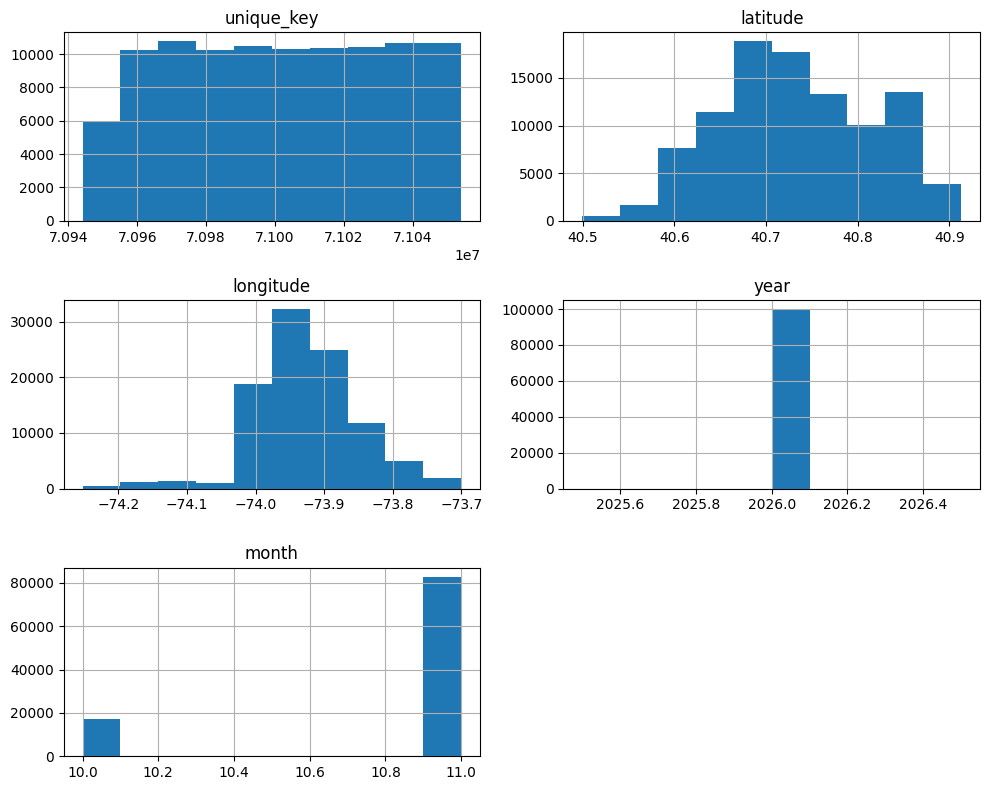


 Statistical Quality check completed


In [ ]:
df.select_dtypes(include='number').hist(figsize=(10,8))
plt.tight_layout()
plt.show()

print("\n Statistical Quality check completed")

# Analyst Task

**1. Total distinct request volume.**


In [ ]:
import pandas as pd

# Explicitly load the cleaned data to prevent NameError in case of kernel restarts
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# Calculate total distinct requests using pandas
total_distinct = df['unique_key'].nunique()

print("Total Distinct Requests:", total_distinct)

Total Distinct Requests: 99997


Total Distinct Request Volume: 99997


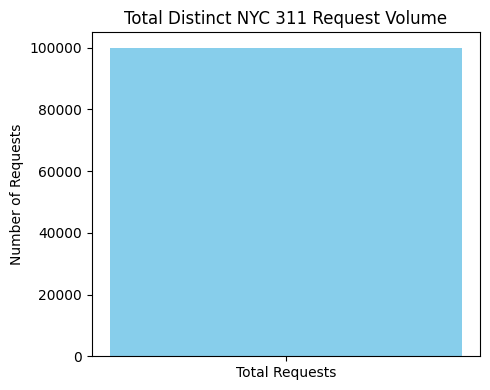

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# 2. Calculate the total distinct requests using pandas nunique on 'unique_key'
total = df['unique_key'].nunique()

print("Total Distinct Request Volume:", total)

# 3. Plot the result
plt.figure(figsize=(5, 4))
plt.bar(["Total Requests"], [total], color='skyblue')

plt.title("Total Distinct NYC 311 Request Volume")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

**2. Top 10 complaint categories by count.**


            complaint_type  total
0          Illegal Parking  18411
1      Noise - Residential  12176
2           HEAT/HOT WATER   6814
3         Blocked Driveway   5534
4  Noise - Street/Sidewalk   4803
5     UNSANITARY CONDITION   3787
6       Noise - Commercial   2205
7                    Noise   2079
8                 PLUMBING   1904
9        Abandoned Vehicle   1861


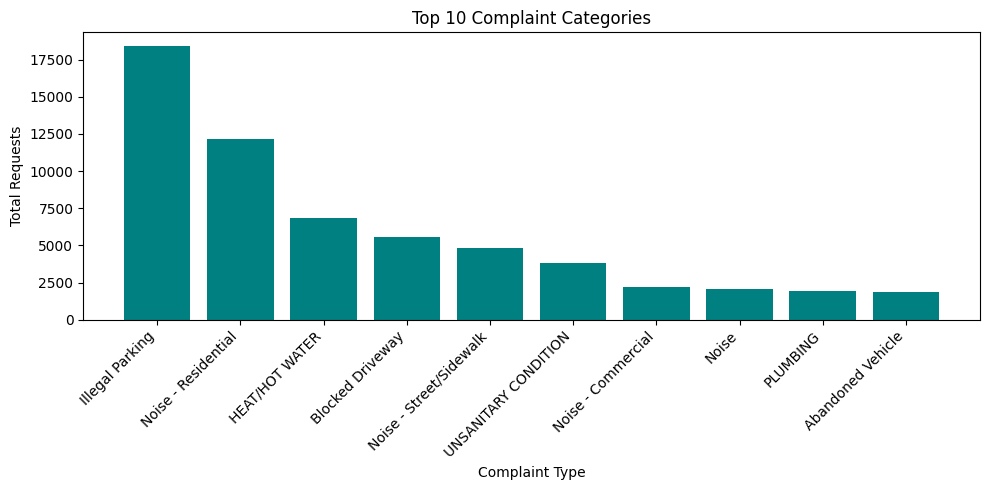

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# 2. Get the top 10 complaint categories by count using native Pandas
top_complaints = (
    df['complaint_type']
    .value_counts()
    .head(10)
    .reset_index(name='total')
)

print(top_complaints)

# 3. Plot the top 10 complaint categories
plt.figure(figsize=(10, 5))
plt.bar(top_complaints['complaint_type'], top_complaints['total'], color='teal')

plt.title("Top 10 Complaint Categories")
plt.xlabel("Complaint Type")
plt.ylabel("Total Requests")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**3. Agency workload distribution.**

   agency  total
0    NYPD  49650
1     HPD  20943
2    DSNY   7248
3     DOT   5704
4     DEP   4799
5     DHS   2694
6     DOB   2548
7     DPR   2287
8   DOHMH   2272
9     TLC   1071
10   DCWP    582
11    OOS    117
12    EDC     72
13    OTI     10


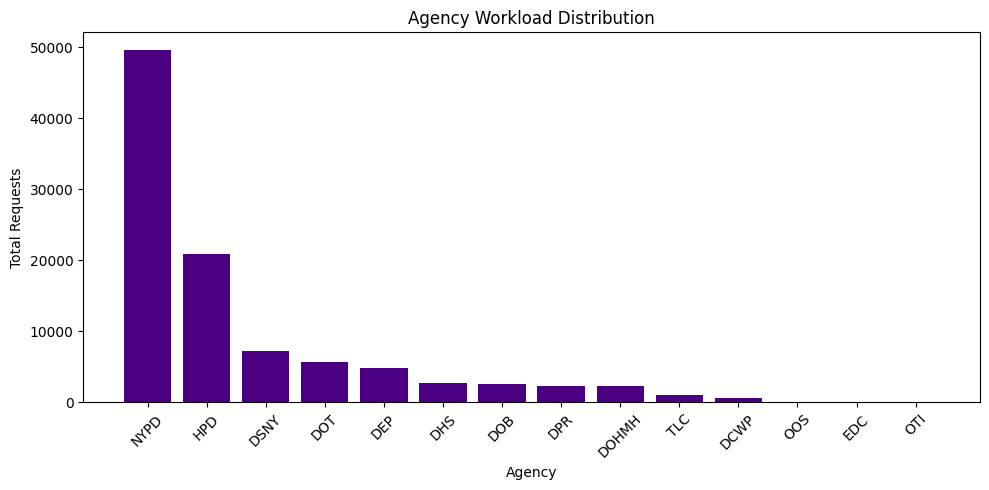

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# 2. Get the workload distribution by agency using native Pandas
agency_workload = (
    df['agency']
    .value_counts()
    .reset_index(name='total')
)

print(agency_workload)

# 3. Plot the workload distribution
plt.figure(figsize=(10, 5))
plt.bar(agency_workload['agency'], agency_workload['total'], color='indigo')

plt.title("Agency Workload Distribution")
plt.xlabel("Agency")
plt.ylabel("Total Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**4. Request volume by borough.**


         borough  requests
0       BROOKLYN     31634
1         QUEENS     23752
2      MANHATTAN     22354
3          BRONX     18584
4  STATEN ISLAND      3576
5    Unspecified        97


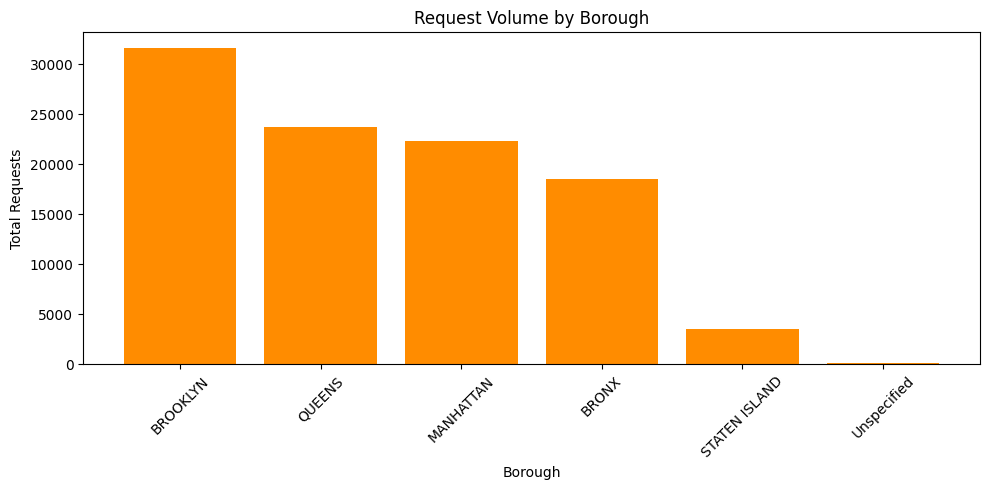

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# 2. Calculate request volume by borough using native Pandas
# (Filters out nulls, groups by borough, and orders in descending order)
borough_volume = (
    df['borough']
    .dropna()
    .value_counts()
    .reset_index(name='requests')
)

print(borough_volume)

# 3. Plot the request volume by borough
plt.figure(figsize=(10, 5))
plt.bar(borough_volume['borough'], borough_volume['requests'], color='darkorange')

plt.title("Request Volume by Borough")
plt.xlabel("Borough")
plt.ylabel("Total Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**5. Monthly request trend.**


  month_period  requests
0      2026-10     17130
1      2026-11     82867


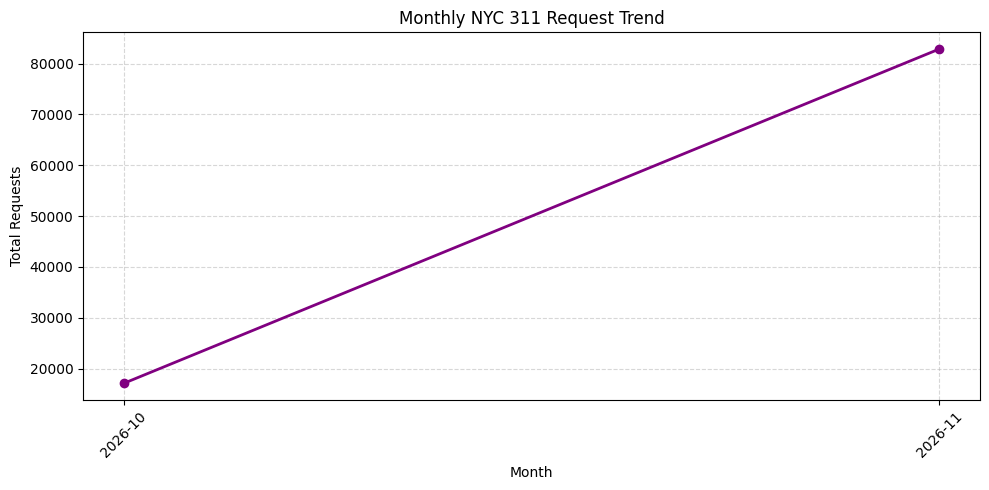

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# Ensure created_date is parsed as a datetime object
df['created_date'] = pd.to_datetime(df['created_date'])

# 2. Extract Year-Month and calculate distinct requests (using native Pandas)
df['month_period'] = df['created_date'].dt.strftime('%Y-%m')

monthly_trend = (
    df.dropna(subset=['created_date'])
    .groupby('month_period')['unique_key']
    .nunique()
    .reset_index(name='requests')
    .sort_values('month_period')
)

print(monthly_trend)

# 3. Plot the monthly NYC 311 Request Trend
plt.figure(figsize=(10, 5))
plt.plot(monthly_trend['month_period'], monthly_trend['requests'], marker='o', color='purple', linewidth=2)

plt.title("Monthly NYC 311 Request Trend")
plt.xlabel("Month")
plt.ylabel("Total Requests")
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Referencing the correct aggregated DataFrame: monthly_trend
print("Highest request month:")
print(monthly_trend.loc[monthly_trend['requests'].idxmax()])

print("\nLowest request month:")
print(monthly_trend.loc[monthly_trend['requests'].idxmin()])

Highest request month:
month_period    2026-11
requests          82867
Name: 1, dtype: object

Lowest request month:
month_period    2026-10
requests          17130
Name: 0, dtype: object


**6. Demand by weekday and hour.**


     weekday  total
1     Monday  12209
5    Tuesday  10026
6  Wednesday  10920
4   Thursday  10520
0     Friday  15493
2   Saturday  20341
3     Sunday  20488


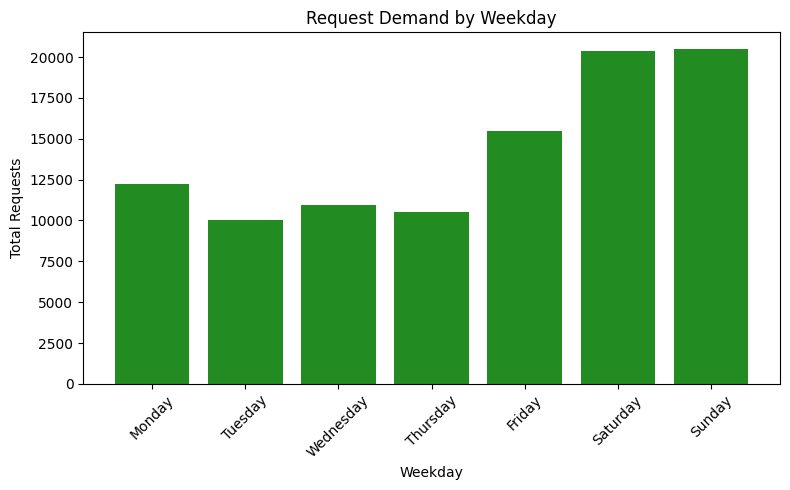

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# Ensure created_date is parsed as datetime
df['created_date'] = pd.to_datetime(df['created_date'])

# 2. Extract day names and count requests per weekday using native Pandas
df['weekday'] = df['created_date'].dt.day_name()

weekday_counts = (
    df.dropna(subset=['created_date'])
    .groupby('weekday')['unique_key']
    .count()
    .reset_index(name='total')
)

# Sort weekdays chronologically
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts['weekday'] = pd.Categorical(weekday_counts['weekday'], categories=weekday_order, ordered=True)
weekday_counts = weekday_counts.sort_values('weekday')

print(weekday_counts)

# 3. Plot the weekday request volume
plt.figure(figsize=(8, 5))
plt.bar(weekday_counts['weekday'], weekday_counts['total'], color='forestgreen')

plt.title("Request Demand by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

    hour  total
0      0   3587
1      1   3084
2      2   1600
3      3   1257
4      4   1338
5      5   1556
6      6   2371
7      7   3451
8      8   4705
9      9   5439
10    10   5633
11    11   6237
12    12   5266
13    13   5305
14    14   5392
15    15   5176
16    16   5128
17    17   4844
18    18   4643
19    19   4329
20    20   4791
21    21   5095
22    22   5274
23    23   4496


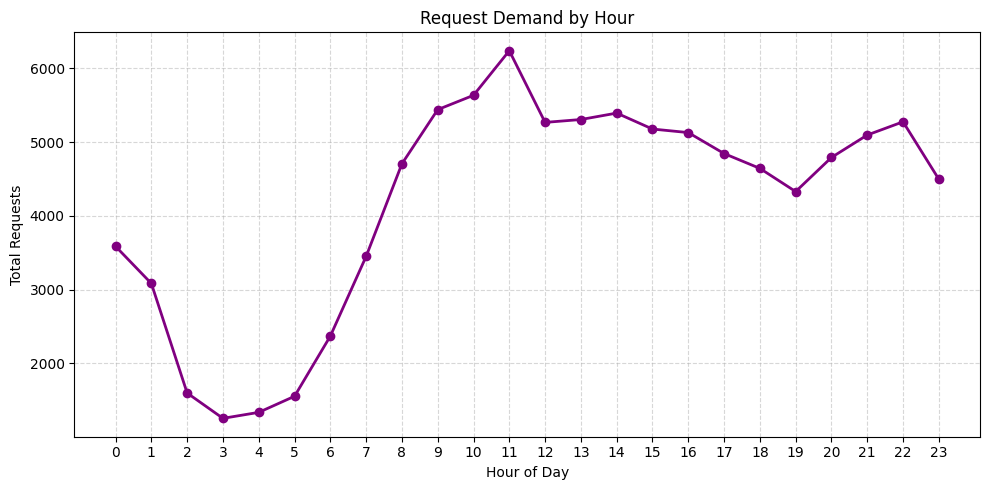

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# Ensure created_date is parsed as datetime
df['created_date'] = pd.to_datetime(df['created_date'])

# 2. Extract hour and calculate total requests per hour using native Pandas
df['hour'] = df['created_date'].dt.hour

hour_counts = (
    df.dropna(subset=['created_date'])
    .groupby('hour')['unique_key']
    .count()
    .reset_index(name='total')
    .sort_values('hour')
)

print(hour_counts)

# 3. Plot the hourly request distribution
plt.figure(figsize=(10, 5))
plt.plot(hour_counts['hour'], hour_counts['total'], marker='o', color='purple', linewidth=2)

plt.title("Request Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Requests")
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**7. Distribution of recorded request statuses.**


        status  total_requests
0       Closed           72435
1         Open           15269
2  In Progress           12017
3     Assigned             247
4      Pending              21
5  Unspecified               8


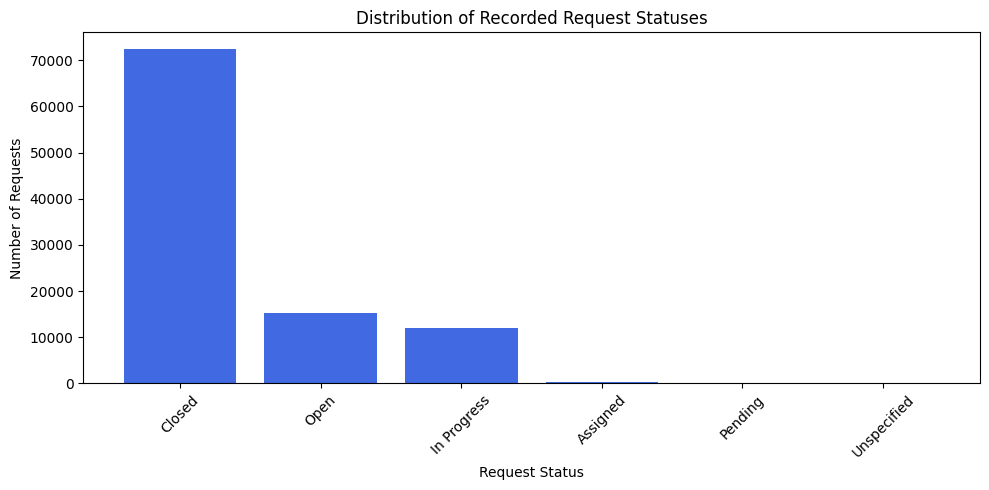

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")

# 2. Aggregating the status count to define 'df_status'
df_status = (
    df['status']
    .value_counts()
    .reset_index(name='total_requests')
)

print(df_status)

# 3. Plotting the distribution
plt.figure(figsize=(10, 5))

plt.bar(
    df_status['status'],
    df_status['total_requests'],
    color='royalblue'
)

plt.title('Distribution of Recorded Request Statuses')
plt.xlabel('Request Status')
plt.ylabel('Number of Requests')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**8. Descriptive statistics for valid resolution durations.**


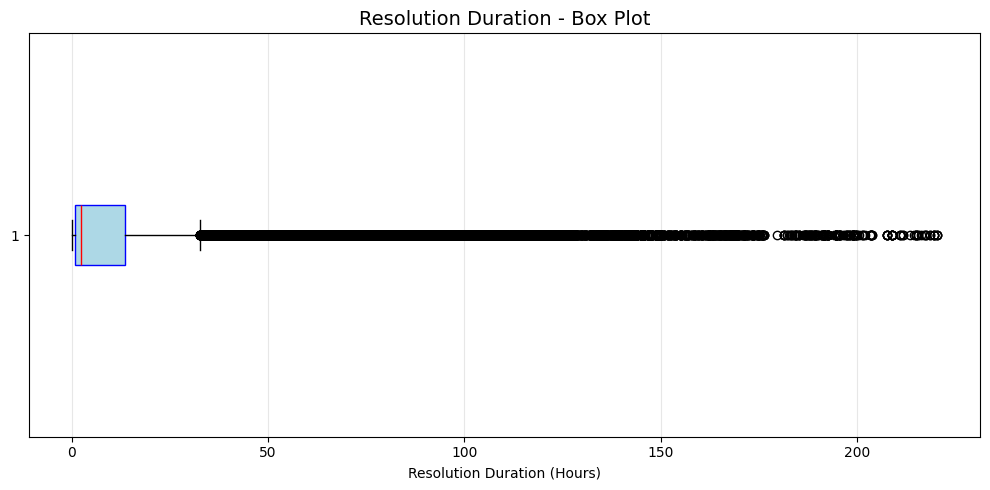

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    print("Cleaned dataset not found. Falling back to raw dataset...")
    df = pd.read_csv("nyc311_row_sample.csv")

# 2. Parse dates and calculate resolution hours
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')

# Create the resolution dataframe with a calculated duration column
df_resolution = df.dropna(subset=['created_date', 'closed_date']).copy()
df_resolution['resolution_hours'] = (df_resolution['closed_date'] - df_resolution['created_date']).dt.total_seconds() / 3600

# Filter out invalid or negative durations
df_resolution = df_resolution[df_resolution['resolution_hours'] >= 0]

# 3. Plot the distribution of resolution times
plt.figure(figsize=(10, 5))

plt.boxplot(
    df_resolution['resolution_hours'],
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='blue'),
    medianprops=dict(color='red')
)

plt.title('Resolution Duration - Box Plot', fontsize=14)
plt.xlabel('Resolution Duration (Hours)')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**9. Median resolution duration by complaint category.**


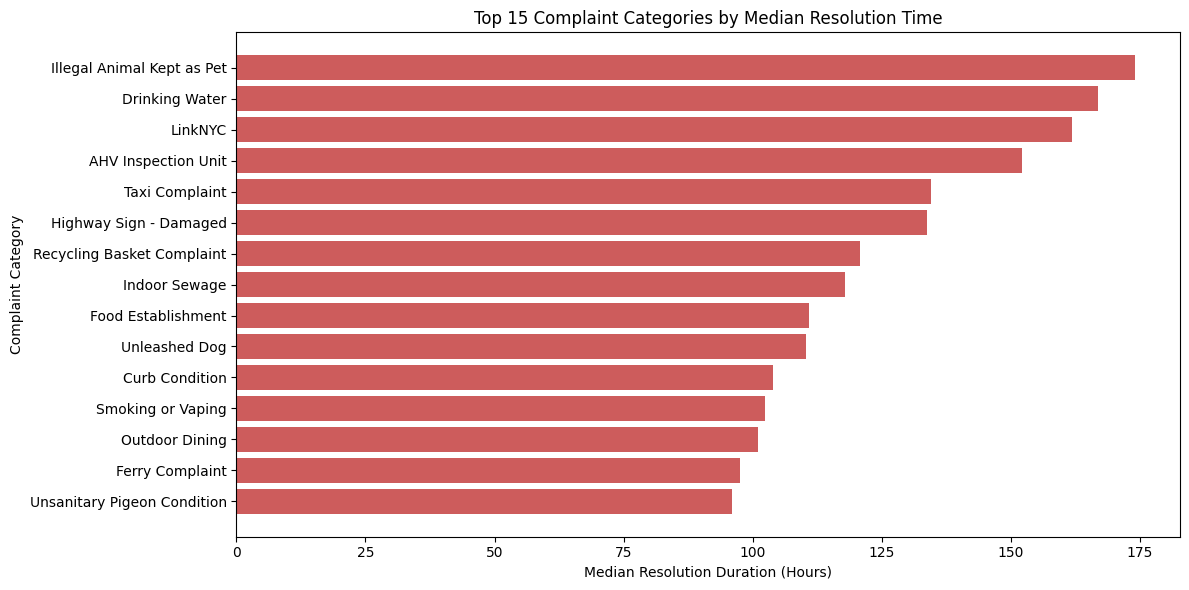

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    # Fallback if the cleaned file is not found
    print("Cleaned dataset not found. Attempting to use the raw dataset instead...")
    df = pd.read_csv("nyc311_row_sample.csv")

# Convert dates to datetime objects
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')

# Calculate resolution hours
df['hours'] = (df['closed_date'] - df['created_date']).dt.total_seconds() / 3600

# Filter out invalid records
df_filtered = df[
    df['created_date'].notna() &
    df['closed_date'].notna() &
    (df['hours'] >= 0) &
    df['complaint_type'].notna()
]

# Calculate median resolution hours and total complaints by complaint category
result = df_filtered.groupby('complaint_type').agg(
    median_hours=('hours', 'median'),
    total_complaints=('hours', 'count')
).reset_index()

# Sort results by median resolution time in descending order
result = result.sort_values(by='median_hours', ascending=False)

# 2. Plot the results
plt.figure(figsize=(12, 6))

plt.barh(
    result['complaint_type'].head(15),
    result['median_hours'].head(15),
    color='indianred'
)

plt.title('Top 15 Complaint Categories by Median Resolution Time')
plt.xlabel('Median Resolution Duration (Hours)')
plt.ylabel('Complaint Category')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**10. Median resolution duration by agency.**


Median Resolution Duration by Agency:
agency  median_hours  total_complaints
   DOB          0.00              2548
  NYPD          1.36             48852
   DHS          6.81              2507
   DOT         14.14              2487
   DPR         17.17               495
   DEP         23.07              3030
  DCWP         26.27               148
   HPD         34.70              9170
  DSNY         36.33              5076
 DOHMH         50.48               415
   TLC         60.35               102
   OOS         68.38                 7
   OTI        161.90                 1


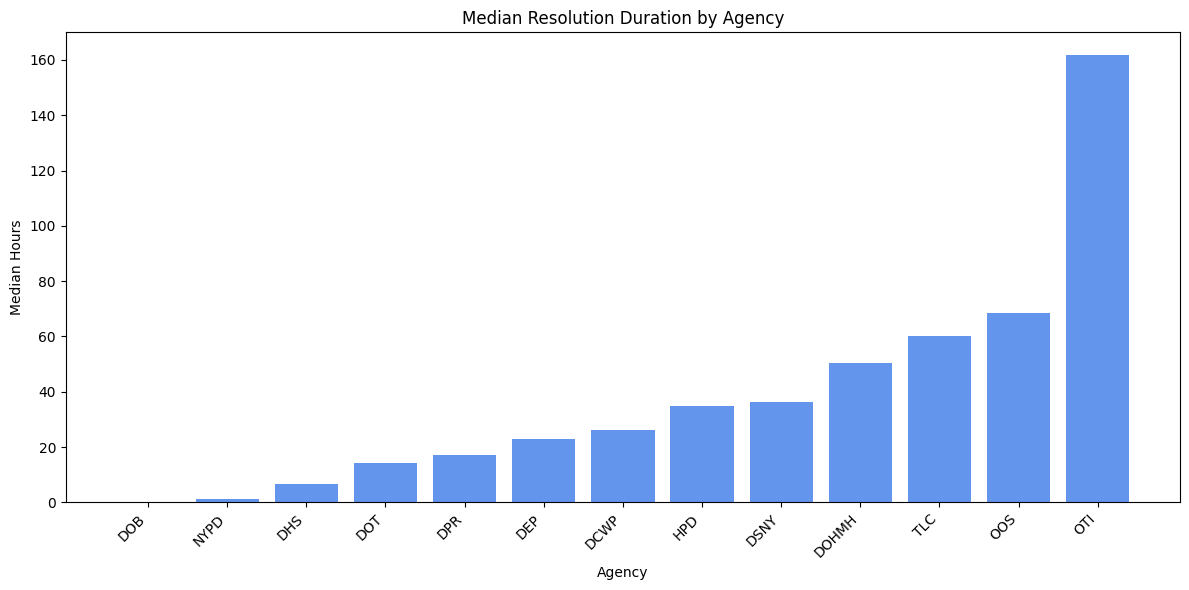

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Instead of connecting to a local MySQL database (which doesn't exist in Colab),
# we load the cleaned dataset directly from the saved CSV file.
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    # Fallback if the file hasn't been generated yet
    print("Cleaned dataset not found. Attempting to use the raw dataset instead...")
    df = pd.read_csv("nyc311_row_sample.csv")

# Convert dates to datetime objects
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')

# Calculate resolution hours
df['hours'] = (df['closed_date'] - df['created_date']).dt.total_seconds() / 3600

# Filter out invalid records (missing dates, negative durations, or missing agency)
df_filtered = df[
    df['created_date'].notna() &
    df['closed_date'].notna() &
    (df['hours'] >= 0) &
    df['agency'].notna()
]

# Calculate median resolution hours and total complaints by agency
median_resolution = df_filtered.groupby('agency').agg(
    median_hours=('hours', 'median'),
    total_complaints=('hours', 'count')
).reset_index()

# Round and sort the results
median_resolution['median_hours'] = median_resolution['median_hours'].round(2)
median_resolution = median_resolution.sort_values(by='median_hours')

# Display output
print("Median Resolution Duration by Agency:")
print(median_resolution.to_string(index=False))

# Plot the median resolution times
plt.figure(figsize=(12, 6))
plt.bar(median_resolution['agency'], median_resolution['median_hours'], color='cornflowerblue')
plt.title('Median Resolution Duration by Agency')
plt.xlabel('Agency')
plt.ylabel('Median Hours')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**11. IQR-based outlier investigation.**


In [ ]:
import pandas as pd

# Instead of SQL database connection, load the dataset directly using Pandas
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    print("Cleaned dataset not found. Falling back to raw dataset...")
    try:
        df = pd.read_csv("nyc311_row_sample.csv")
    except (FileNotFoundError, pd.errors.EmptyDataError):
        df = None
        print("Error: No data available. Please re-run the API scraping steps successfully first.")

if df is not None and not df.empty:
    # Equivalent to SQL WHERE clause filtering out missing dates
    df_filtered = df[df['created_date'].notna() & df['closed_date'].notna()].copy()

    # Calculate resolution hours
    df_filtered['hours'] = (
        pd.to_datetime(df_filtered['closed_date'], errors='coerce') -
        pd.to_datetime(df_filtered['created_date'], errors='coerce')
    ).dt.total_seconds() / 3600

    # Equivalent to SQL WHERE hours >= 0
    df_filtered = df_filtered[df_filtered['hours'] >= 0]

    if not df_filtered.empty:
        # Outlier calculation
        Q1 = df_filtered['hours'].quantile(0.25)
        Q3 = df_filtered['hours'].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = df_filtered[(df_filtered['hours'] < lower) | (df_filtered['hours'] > upper)]

        print("Q1:", Q1)
        print("Q3:", Q3)
        print("IQR:", IQR)
        print("Total Outliers:", len(outliers))
        print(outliers[['created_date', 'closed_date', 'hours']].head(10))
    else:
        print("No valid records found with resolution hours >= 0.")
else:
    print("Could not run analysis: Data is missing or empty.")

Q1: 0.7325
Q3: 13.522083333333335
IQR: 12.789583333333335
Total Outliers: 11436
              created_date          closed_date      hours
14503  2026-11-07 14:24:00  2026-11-09 01:38:00  35.233333
15496  2026-11-07 12:23:06  2026-11-08 21:06:12  32.718333
16067  2026-11-07 11:15:06  2026-11-08 19:58:14  32.718889
16545  2026-11-07 10:25:04  2026-11-08 20:32:56  34.131111
16626  2026-11-07 10:16:29  2026-11-08 20:49:41  34.553333
16812  2026-11-07 09:51:12  2026-11-08 20:00:48  34.160000
17094  2026-11-07 09:16:19  2026-11-08 18:00:29  32.736111
17130  2026-11-07 09:11:38  2026-11-08 18:04:21  32.878611
17170  2026-11-07 09:06:23  2026-11-08 18:04:21  32.966111
17711  2026-11-07 07:58:19  2026-11-08 20:10:24  36.201389


**12. Resolution-time skewness and distribution.**


Mean: 14.858766483753051
Median: 2.4119444444444444
Skewness: 3.0379250932693846


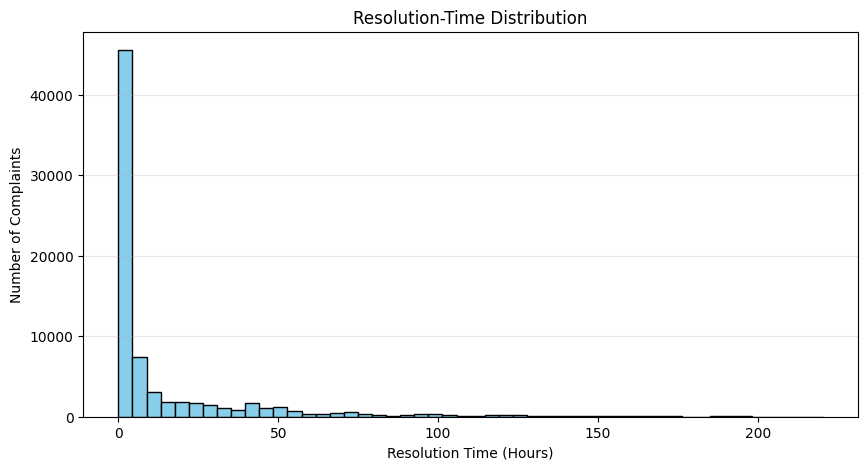

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Instead of SQL database connection, load the dataset directly using Pandas
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    print("Cleaned dataset not found. Falling back to raw dataset...")
    try:
        df = pd.read_csv("nyc311_row_sample.csv")
    except (FileNotFoundError, pd.errors.EmptyDataError):
        df = None
        print("Error: No data available. Please re-run the API scraping steps successfully first.")

if df is not None and not df.empty:
    # Equivalent to SQL WHERE constraints
    df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
    df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')

    df_filtered = df[
        df['created_date'].notna() &
        df['closed_date'].notna() &
        (df['closed_date'] >= df['created_date'])
    ].copy()

    # Calculate resolution hours
    df_filtered['hours'] = (df_filtered['closed_date'] - df_filtered['created_date']).dt.total_seconds() / 3600

    print("Mean:", df_filtered['hours'].mean())
    print("Median:", df_filtered['hours'].median())
    print("Skewness:", df_filtered['hours'].skew())

    # Plot resolution distribution
    plt.figure(figsize=(10, 5))
    plt.hist(df_filtered['hours'], bins=50, color='skyblue', edgecolor='black')
    plt.xlabel("Resolution Time (Hours)")
    plt.ylabel("Number of Complaints")
    plt.title("Resolution-Time Distribution")
    plt.grid(axis='y', alpha=0.3)
    plt.show()
else:
    print("Could not run analysis: Data is missing or empty.")

**13. Geographic complaint concentration using usable coordinates or borough summaries.**


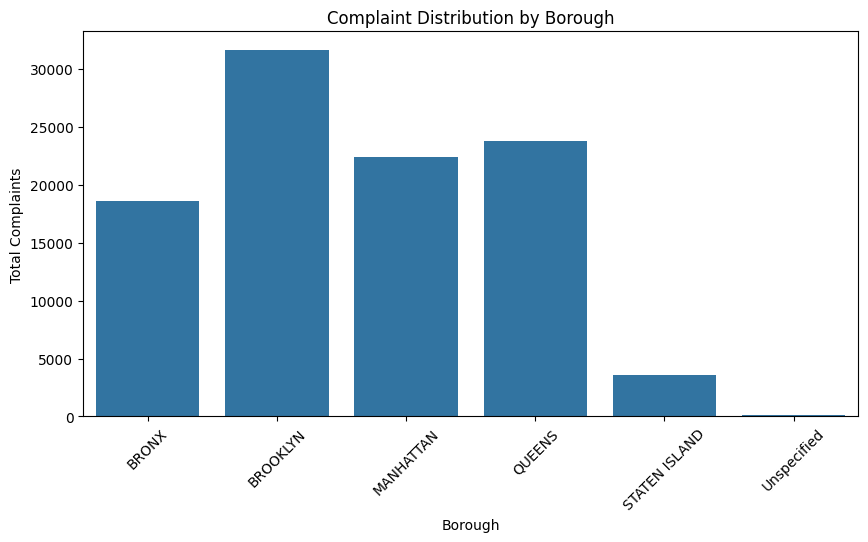

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

borough_data = df.groupby('borough').size().reset_index(name='total_complaints')

plt.figure(figsize=(10,5))

sns.barplot(
    data=borough_data,
    x='borough',
    y='total_complaints'
)

plt.title('Complaint Distribution by Borough')
plt.xlabel('Borough')
plt.ylabel('Total Complaints')
plt.xticks(rotation=45)

plt.show()


**14. Recorded closure-rate comparison.**


   agency  closure_rate
10   NYPD         98.40
2     DHS         93.06
7    DSNY         70.02
1     DEP         52.95
9     HPD         43.79
5     DOT         41.53
3     DOB         29.47
0    DCWP         25.43
6     DPR         21.64
4   DOHMH         18.27
12    OTI         10.00
13    TLC          9.52
11    OOS          5.98
8     EDC          0.00


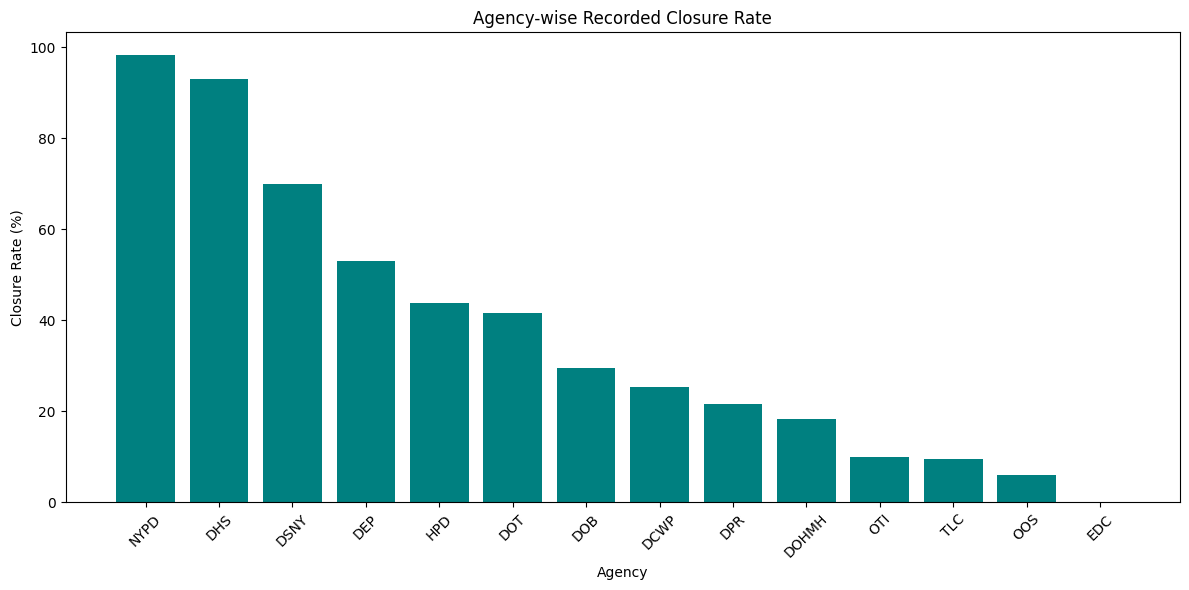

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    df = pd.read_csv("nyc311_row_sample.csv")

# Filter out missing agencies
df_filtered = df[df['agency'].notna()]

# Calculate closure rate per agency using Pandas
# Closure Rate % = (Number of Closed requests / Total requests) * 100
agency_stats = df_filtered.groupby('agency').agg(
    total_requests=('status', 'count'),
    closed_requests=('status', lambda x: (x == 'Closed').sum())
).reset_index()

agency_stats['closure_rate'] = (agency_stats['closed_requests'] / agency_stats['total_requests'] * 100).round(2)

# Sort by closure rate descending
agency_stats = agency_stats.sort_values(by='closure_rate', ascending=False)

# Display the results
print(agency_stats[['agency', 'closure_rate']])

# Plotting
plt.figure(figsize=(12, 6))
plt.bar(agency_stats['agency'], agency_stats['closure_rate'], color='teal')

plt.title('Agency-wise Recorded Closure Rate')
plt.xlabel('Agency')
plt.ylabel('Closure Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**15. Categories with both high request volume and long median resolution duration.**


High Request Volume and Long Resolution Categories:
           complaint_type  total_requests  avg_resolution_hours
77                  Noise            1220             55.256795
30        Dirty Condition            1157             52.093548
115  UNSANITARY CONDITION             935             88.427513
59        Illegal Dumping             710             55.084986


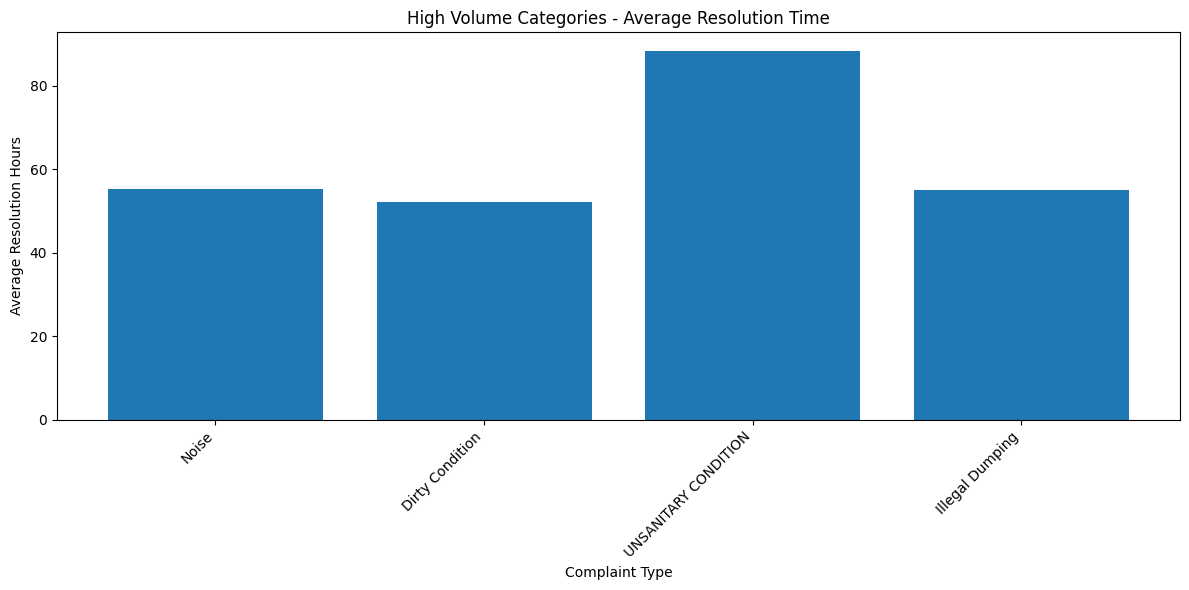

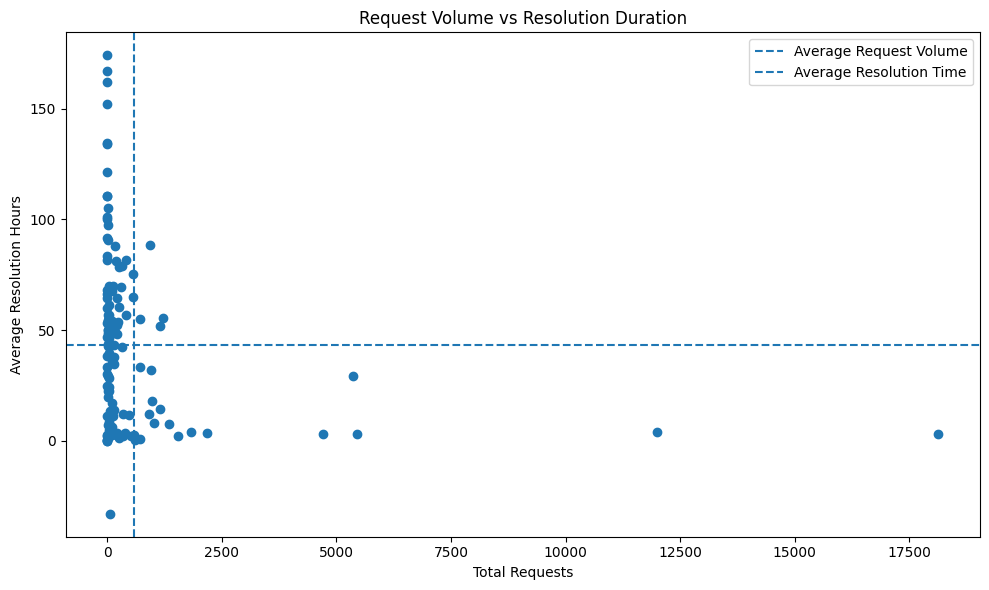

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
try:
    df = pd.read_csv("Urban_Pulse_NYC_Cleaned.csv")
except FileNotFoundError:
    df = pd.read_csv("nyc311_row_sample.csv")

# Convert dates
df['created_date'] = pd.to_datetime(df['created_date'], errors='coerce')
df['closed_date'] = pd.to_datetime(df['closed_date'], errors='coerce')

# Remove null dates
df = df.dropna(subset=['created_date', 'closed_date'])

# Calculate resolution hours
df['resolution_hours'] = (
    df['closed_date'] - df['created_date']
).dt.total_seconds() / 3600

# Group by complaint type
complaint_stats = df.groupby('complaint_type').agg(
    total_requests=('complaint_type', 'count'),
    avg_resolution_hours=('resolution_hours', 'mean')
).reset_index()

# Calculate average thresholds
avg_volume = complaint_stats['total_requests'].mean()
avg_time = complaint_stats['avg_resolution_hours'].mean()

# Filter high-volume and long-resolution categories
result = complaint_stats[
    (complaint_stats['total_requests'] > avg_volume) &
    (complaint_stats['avg_resolution_hours'] > avg_time)
].sort_values(by='total_requests', ascending=False)

print("High Request Volume and Long Resolution Categories:")
print(result)

# Visualization 1: Bar Chart
plt.figure(figsize=(12, 6))

plt.bar(result['complaint_type'],
        result['avg_resolution_hours'])

plt.title('High Volume Categories - Average Resolution Time')
plt.xlabel('Complaint Type')
plt.ylabel('Average Resolution Hours')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Visualization 2: Scatter Plot
plt.figure(figsize=(10, 6))

plt.scatter(
    complaint_stats['total_requests'],
    complaint_stats['avg_resolution_hours']
)

plt.axvline(avg_volume, linestyle='--', label='Average Request Volume')
plt.axhline(avg_time, linestyle='--', label='Average Resolution Time')

plt.title('Request Volume vs Resolution Duration')
plt.xlabel('Total Requests')
plt.ylabel('Average Resolution Hours')
plt.legend()
plt.tight_layout()
plt.show()